In [ ]:
!pip install -q datasets

from datasets import load_dataset

data = load_dataset("data-silence/rus_news_classifier")
df = data["train"].to_pandas()

print(df.head())
print("Number of texts:", len(df))
print(df.columns)

                                                news  labels
0  Житель Москвы сходил на сеанс эротического мас...       1
1  В 2021 году Microsoft выпустит специальную вер...       7
2  Министерство культуры и информационной политик...       2
3  Британский боксер-тяжеловес Тайсон Фьюри оскор...       9
4  Растущая напряженность между Индией и Китаем в...       1
Number of texts: 57530
Index(['news', 'labels'], dtype='object')


In [ ]:

import re

df = df[["news", "labels"]].dropna()
df = df.drop_duplicates(subset="news")

df["news"] = df["news"].str.lower()

df["news"] = df["news"].str.replace(
    r"[^а-яё\s]", " ", regex=True
)

df["news"] = df["news"].str.replace(
    r"\s+", " ", regex=True
)

print(df.head())
print("Texts remaining:", len(df))

                                                news  labels
0  житель москвы сходил на сеанс эротического мас...       1
1  в году выпустит специальную версию для бюджетн...       7
2  министерство культуры и информационной политик...       2
3  британский боксер тяжеловес тайсон фьюри оскор...       9
4  растущая напряженность между индией и китаем в...       1
Texts remaining: 57170


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    df["news"],
    df["labels"],
    test_size=0.2,
    random_state=42,
    stratify=df["labels"]
)

tfidf = TfidfVectorizer(max_features=3000)

X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

print("Training documents:", X_train.shape[0])
print("Testing documents:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training documents: 45736
Testing documents: 11434
Number of features: 3000


In [ ]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

model1 = MultinomialNB()
model2 = LogisticRegression(max_iter=500)

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)

pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)

print("NAIVE BAYES")
print("Accuracy:", round(accuracy_score(y_test, pred1), 3))
print("F1 score:", round(f1_score(y_test, pred1, average="macro"), 3))

print("\nLOGISTIC REGRESSION")
print("Accuracy:", round(accuracy_score(y_test, pred2), 3))
print("F1 score:", round(f1_score(y_test, pred2, average="macro"), 3))

NAIVE BAYES
Accuracy: 0.753
F1 score: 0.759

LOGISTIC REGRESSION
Accuracy: 0.814
F1 score: 0.819


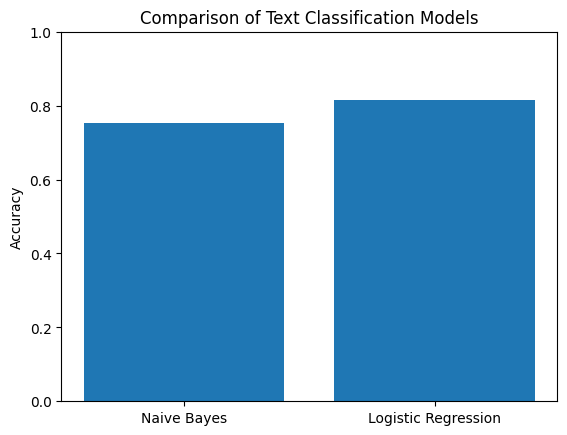

In [ ]:

import matplotlib.pyplot as plt

scores = [
    accuracy_score(y_test, pred1),
    accuracy_score(y_test, pred2)
]

plt.bar(["Naive Bayes", "Logistic Regression"], scores)
plt.ylabel("Accuracy")
plt.title("Comparison of Text Classification Models")
plt.ylim(0, 1)
plt.show()

Naive Bayes accuracy: 0.759
Naive Bayes F1: 0.764
Logistic Regression accuracy: 0.813
Logistic Regression F1: 0.818


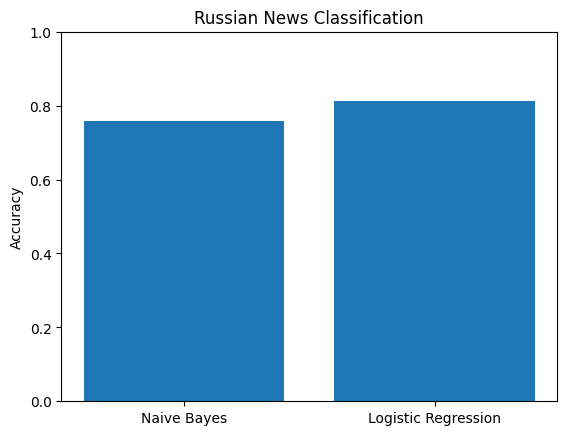

Number of documents: 57170
Number of categories: 11


In [ ]:

import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

nltk.download("stopwords", quiet=True)
russian_stopwords = stopwords.words("russian")

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["news"], df["labels"],
    test_size=0.2,
    random_state=42,
    stratify=df["labels"]
)

tfidf = TfidfVectorizer(
    max_features=3000,
    stop_words=russian_stopwords
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

model1 = MultinomialNB()
model2 = LogisticRegression(max_iter=500)

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)

pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)

print("Naive Bayes accuracy:",
      round(accuracy_score(y_test, pred1), 3))
print("Naive Bayes F1:",
      round(f1_score(y_test, pred1, average="macro"), 3))

print("Logistic Regression accuracy:",
      round(accuracy_score(y_test, pred2), 3))
print("Logistic Regression F1:",
      round(f1_score(y_test, pred2, average="macro"), 3))

plt.bar(
    ["Naive Bayes", "Logistic Regression"],
    [accuracy_score(y_test, pred1),
     accuracy_score(y_test, pred2)]
)
plt.title("Russian News Classification")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

print("Number of documents:", len(df))
print("Number of categories:", df["labels"].nunique())